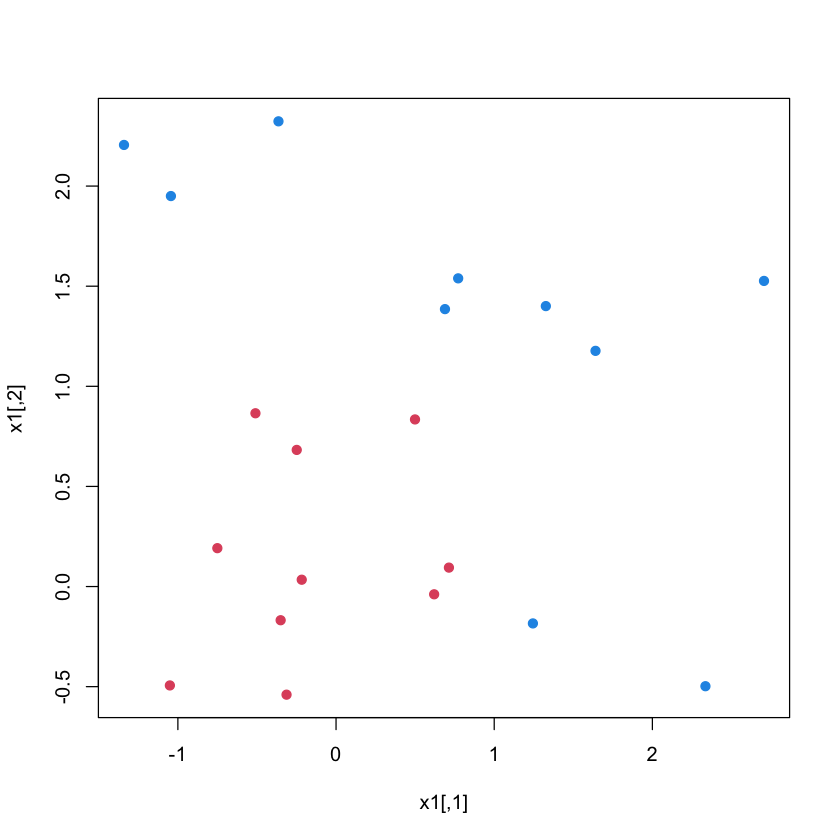

In [1]:
library(e1071)

set.seed(10111)
x1 <- matrix(rnorm(40), 20, 2)
y1 <- rep(c(-1, 1), c(10, 10))
x1[y1 == 1, ] <- x1[y1 == 1, ] + 1
plot(x1, col = y1 + 3, pch = 19)


Call:
svm(formula = y ~ ., data = dat1, kernel = "linear", cost = 10, scale = FALSE)


Parameters:
   SVM-Type:  C-classification 
 SVM-Kernel:  linear 
       cost:  10 

Number of Support Vectors:  6

 ( 3 3 )


Number of Classes:  2 

Levels: 
 -1 1




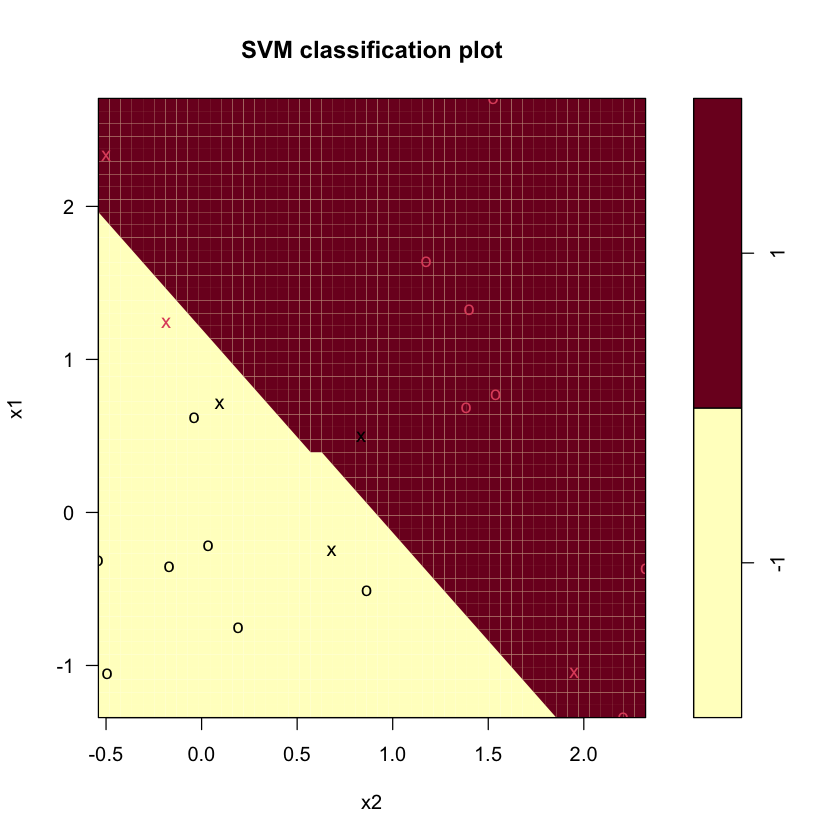

In [2]:
# y must be a factor so svm() does classification, not regression
dat1 <- data.frame(x1 = x1[, 1], x2 = x1[, 2], y = as.factor(y1))

svm.lin <- svm(y ~ ., data = dat1, kernel = "linear", cost = 10, scale = FALSE)
summary(svm.lin)
plot(svm.lin, dat1)

[1] "dat1"        "ESL.mixture" "svm.lin"     "x1"          "y1"

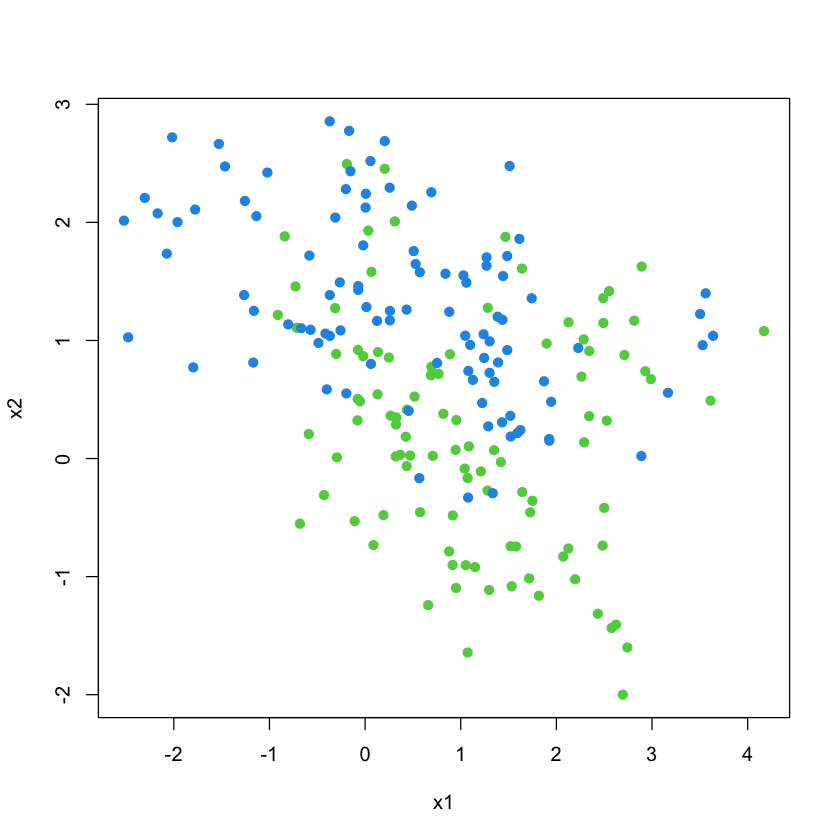

In [4]:
# Download ESL.mixture.rda from Canvas > Modules > Data first
load("/Users/emilyahmad/DataScience/OM065-Data-Science/Data/ESL.mixture.rda")
ls()   # contains x, y, xnew, prob, px1, px2, means, ...

dat <- data.frame(x1 = ESL.mixture$x[, 1],
                  x2 = ESL.mixture$x[, 2],
                  y  = as.factor(ESL.mixture$y))
# If load() put x and y directly in your workspace instead, use:
# dat <- data.frame(x1 = x[, 1], x2 = x[, 2], y = as.factor(y))

plot(dat$x1, dat$x2, col = as.numeric(dat$y) + 2, pch = 19,
     xlab = "x1", ylab = "x2")

In [5]:
library(caret)

set.seed(123)
prop.index <- createDataPartition(dat$y, p = 0.8,
                                  list = FALSE,
                                  times = 1)
train <- dat[prop.index, ]
test  <- dat[-prop.index, ]

Loading required package: ggplot2


Attaching package: ‘ggplot2’


The following object is masked from ‘package:e1071’:

    element


Loading required package: lattice




Call:
svm(formula = y ~ ., data = train, kernel = "radial", scale = FALSE)


Parameters:
   SVM-Type:  C-classification 
 SVM-Kernel:  radial 
       cost:  1 

Number of Support Vectors:  101

 ( 50 51 )


Number of Classes:  2 

Levels: 
 0 1




         actual
predicted  0  1
        0 14  2
        1  6 18

[1] 0.8

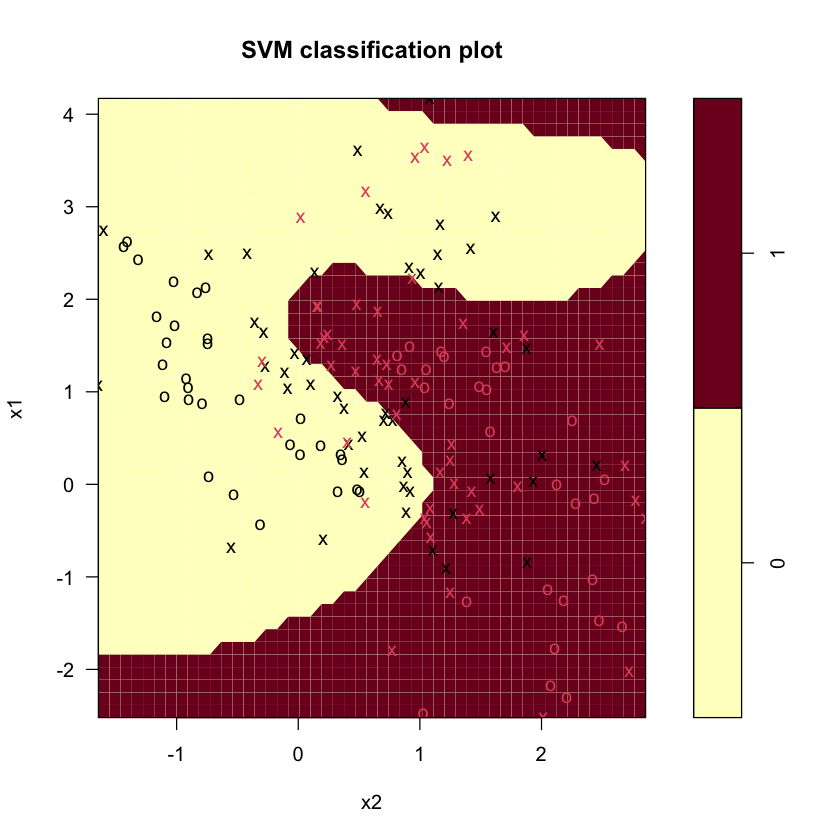

In [6]:
svm.fit <- svm(y ~ ., data = train, scale = FALSE, kernel = "radial")
summary(svm.fit)
plot(svm.fit, train)

pred0 <- predict(svm.fit, test)
table(predicted = pred0, actual = test$y)
mean(pred0 == test$y)

[1] 0.8


Parameter tuning of ‘svm’:

- sampling method: 10-fold cross validation 

- best parameters:
 cost gamma
    1     2

- best performance: 0.15625 

- Detailed performance results:
    cost gamma   error dispersion
1  1e-01  0.01 0.52500 0.14493773
2  1e+00  0.01 0.30000 0.10120798
3  1e+01  0.01 0.30000 0.08740074
4  1e+02  0.01 0.29375 0.05929271
5  1e+03  0.01 0.25625 0.09057110
6  1e-01  0.10 0.31250 0.10622957
7  1e+00  0.10 0.29375 0.08359334
8  1e+01  0.10 0.23750 0.11711224
9  1e+02  0.10 0.23750 0.12430362
10 1e+03  0.10 0.24375 0.14863382
11 1e-01  0.50 0.25625 0.09969572
12 1e+00  0.50 0.21250 0.09409658
13 1e+01  0.50 0.20000 0.09223310
14 1e+02  0.50 0.17500 0.10120798
15 1e+03  0.50 0.20625 0.12517349
16 1e-01  1.00 0.21250 0.11102427
17 1e+00  1.00 0.16875 0.10227448
18 1e+01  1.00 0.18750 0.10206207
19 1e+02  1.00 0.21250 0.09860133
20 1e+03  1.00 0.20625 0.08359334
21 1e-01  2.00 0.19375 0.09524275
22 1e+00  2.00 0.15625 0.09432693
23 1e+01  2.00 0.20000 0.07682954
24 

,cost,gamma
,<dbl>,<dbl>
22,1,2


[1] 0.85

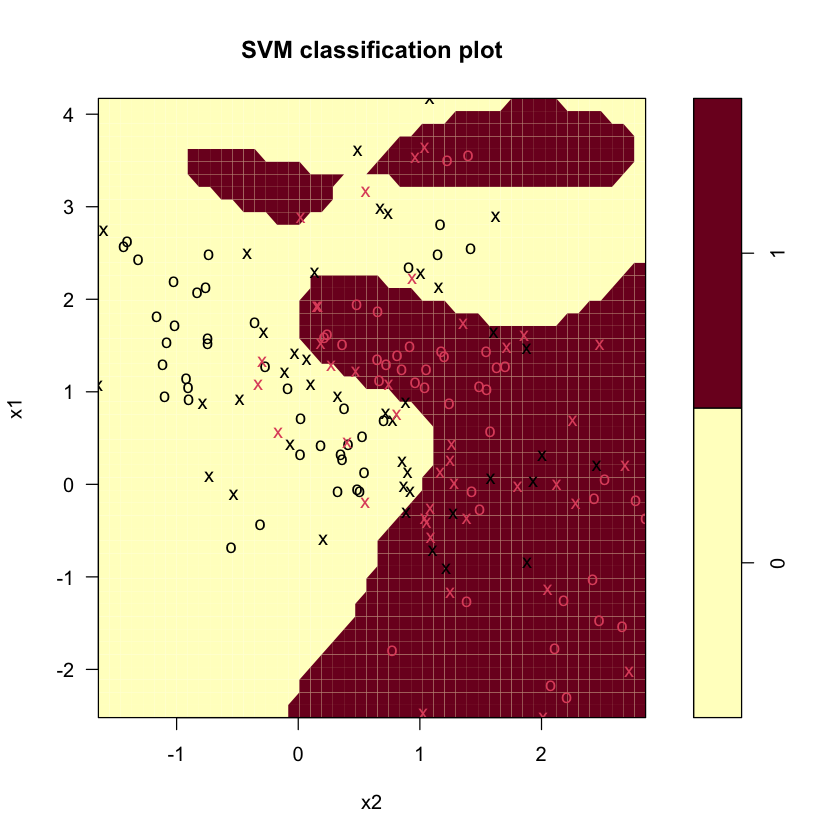

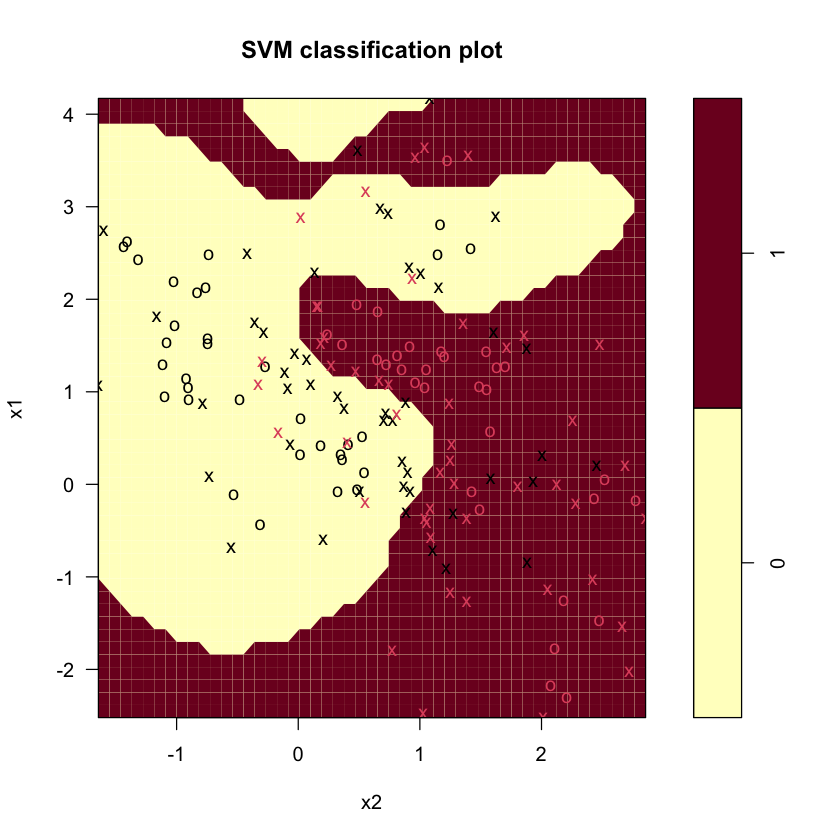

In [7]:
# Manual tries
svm.fit2 <- svm(y ~ ., data = train, scale = FALSE, kernel = "radial",
                cost = 10, gamma = 1)
mean(predict(svm.fit2, test) == test$y)
plot(svm.fit2, train)

# Systematic search with cross-validation
set.seed(123)
tune.out <- tune(svm, y ~ ., data = train, scale = FALSE, kernel = "radial",
                 ranges = list(cost  = c(0.1, 1, 10, 100, 1000),
                               gamma = c(0.01, 0.1, 0.5, 1, 2, 5)))
summary(tune.out)
tune.out$best.parameters

svm.best <- tune.out$best.model
mean(predict(svm.best, test) == test$y)
plot(svm.best, train)

Type 'citation("pROC")' for a citation.


Attaching package: ‘pROC’


The following objects are masked from ‘package:stats’:

    cov, smooth, var




Area under the curve: 0.855

Area under the curve: 0.8625

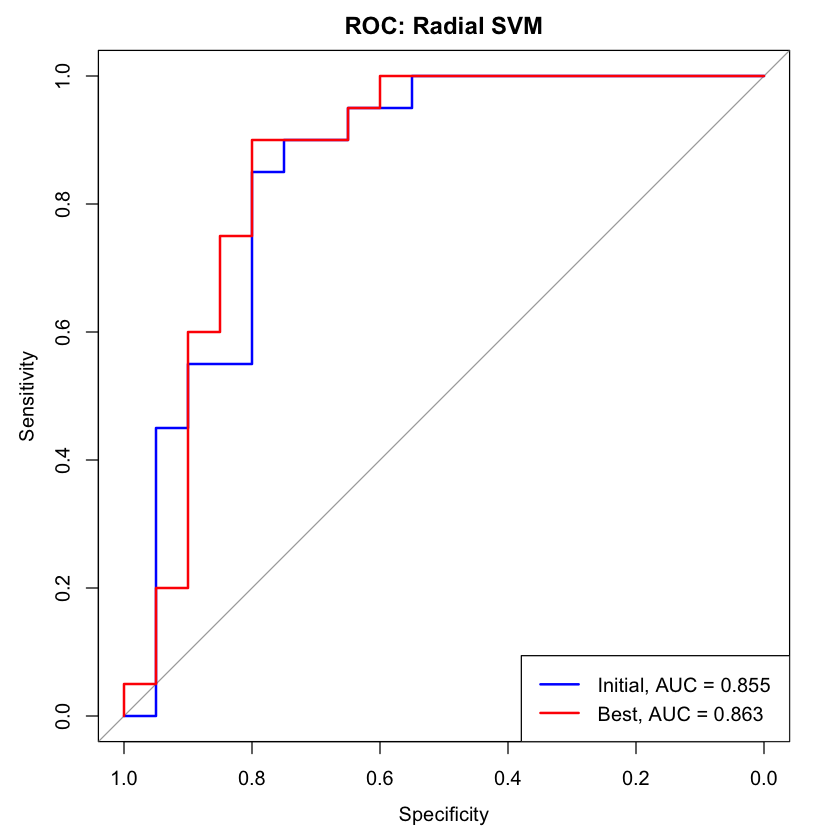

In [8]:
library(pROC)

# Refit with decision values available
svm.init <- svm(y ~ ., data = train, scale = FALSE, kernel = "radial")

get_dv <- function(model, newdata) {
  p <- predict(model, newdata, decision.values = TRUE)
  as.numeric(attr(p, "decision.values"))
}

dv.init <- get_dv(svm.init, test)
dv.best <- get_dv(svm.best, test)

roc.init <- roc(test$y, dv.init, quiet = TRUE)
roc.best <- roc(test$y, dv.best, quiet = TRUE)

plot(roc.init, col = "blue", lwd = 2, main = "ROC: Radial SVM")
plot(roc.best, col = "red", lwd = 2, add = TRUE)
legend("bottomright", lwd = 2, col = c("blue", "red"),
       legend = c(paste("Initial, AUC =", round(auc(roc.init), 3)),
                  paste("Best, AUC =", round(auc(roc.best), 3))))

auc(roc.init)
auc(roc.best)

# SVM Breakouts Contd

In [10]:
data(iris)
str(iris)          # confirm: 150 obs, 4 numeric predictors + Species factor
table(iris$Species)
head(iris)

'data.frame':	150 obs. of  5 variables:
 $ Sepal.Length: num  5.1 4.9 4.7 4.6 5 5.4 4.6 5 4.4 4.9 ...
 $ Sepal.Width : num  3.5 3 3.2 3.1 3.6 3.9 3.4 3.4 2.9 3.1 ...
 $ Petal.Length: num  1.4 1.4 1.3 1.5 1.4 1.7 1.4 1.5 1.4 1.5 ...
 $ Petal.Width : num  0.2 0.2 0.2 0.2 0.2 0.4 0.3 0.2 0.2 0.1 ...
 $ Species     : Factor w/ 3 levels "setosa","versicolor",..: 1 1 1 1 1 1 1 1 1 1 ...



    setosa versicolor  virginica 
        50         50         50 

,Sepal.Length,Sepal.Width,Petal.Length,Petal.Width,Species
,<dbl>,<dbl>,<dbl>,<dbl>,<fct>
1,5.1,3.5,1.4,0.2,setosa
2,4.9,3.0,1.4,0.2,setosa
3,4.7,3.2,1.3,0.2,setosa
4,4.6,3.1,1.5,0.2,setosa
5,5.0,3.6,1.4,0.2,setosa
6,5.4,3.9,1.7,0.4,setosa


In [12]:
set.seed(123)
idx = createDataPartition(iris$Species, p=.8, list = FALSE)
train = iris[idx,]
rest = iris[-idx,]

In [14]:
svm.fit
svm = svm(Species ~., data=train, type = "C-classification", kernel="radial")
summary(svm.fit)

pred = predict(svm.fit, test)
mean(pred == test$Species)
svm.fit$tot.nSV
svm.fit$nSV


Call:
svm(formula = y ~ ., data = train, kernel = "radial", scale = FALSE)


Parameters:
   SVM-Type:  C-classification 
 SVM-Kernel:  radial 
       cost:  1 

Number of Support Vectors:  101



Call:
svm(formula = y ~ ., data = train, kernel = "radial", scale = FALSE)


Parameters:
   SVM-Type:  C-classification 
 SVM-Kernel:  radial 
       cost:  1 

Number of Support Vectors:  101

 ( 50 51 )


Number of Classes:  2 

Levels: 
 0 1




[1] NaN

[1] 101

[1] 50 51

In [16]:
grid = expand.grid(cost = c(0.1, 1, 10, 100), gamma = c(0.01, 0.1, 0.5, 1, 5))
grid$test_acc = NA
grid$nSV = NA

In [21]:
# Manual grid, recording accuracy and support vectors
grid <- expand.grid(cost = c(0.1, 1, 10, 100), gamma = c(0.01, 0.1, 0.5, 1, 5))
grid$test_acc <- NA
grid$nSV <- NA

for (i in seq_len(nrow(grid))) {
  m <- svm(Species ~ ., data = train, type = "C-classification",
           kernel = "radial", cost = grid$cost[i], gamma = grid$gamma[i])
  grid$test_acc[i] <- mean(predict(m, test) == test$Species)
  grid$nSV[i] <- m$tot.nSV
}
grid[order(-grid$test_acc), ]

ERROR: Error in eval(predvars, data, env): object 'Sepal.Length' not found
